# 04 — Proximal Policy Optimization (PPO) in JAX

**CartPole-v1 · JAX / Flax / Optax / Gymnax**

This notebook implements clipped PPO from scratch, including vectorized collection, correct GAE with episode-boundary masking, shuffled minibatches, multiple optimization epochs, value clipping, entropy, and approximate-KL monitoring. We compare PPO against an *unclipped surrogate* with the **same multiple-epoch optimization** (not a fully on-policy vanilla actor-critic baseline), and sweep the clipping threshold.

Run top-to-bottom. Training and evaluation are executable cells; optional sweeps are disabled by default to reduce runtime. CPU-compatible. **Note:** The notebook is syntax-checked, but full training was not executed in the authoring environment.

In [1]:
# Uncomment if needed, run once, and restart the kernel.
# %pip install -q "jax>=0.4.30" "flax>=0.10" "optax>=0.2.3" "gymnax>=0.0.8" matplotlib pandas


## 1. PPO mathematics

Given data sampled from the old policy $\pi_{\theta_{\rm old}}$, let

$r_t(\theta)=\exp[\log\pi_\theta(a_t|s_t)-\log\pi_{\theta_{\rm old}}(a_t|s_t)]$.

The clipped PPO surrogate is

$L^{\rm CLIP}(\theta)=\mathbb E[\min(r_t\hat A_t,\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t)]$.

For an unclipped comparison use $L^{\rm PG}=\mathbb E[r_t\hat A_t]$. The actor minimizes $-L$.

With $\delta_t=r_t^{\rm reward}+\gamma(1-d_t)V(s_{t+1})-V(s_t)$, GAE satisfies

$\hat A_t=\delta_t+\gamma\lambda(1-d_t)\hat A_{t+1}$.

The critic target is $\hat R_t=\hat A_t+V_{\rm old}(s_t)$, held fixed during PPO epochs. Optionally clip the value prediction to $V_{\rm old}\pm\epsilon_v$. The total loss is

$\mathcal L=-L^{\rm CLIP}+c_v L_V-c_e\mathcal H$.

**Important:** old log-probabilities, values, advantages, and targets must remain fixed throughout the minibatch epochs. GAE must never bootstrap across episode terminations. At a nonterminal *rollout boundary*, the final state value is used for bootstrapping.

In [2]:
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import gymnax
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from functools import partial

print('JAX:', jax.__version__, '| devices:', jax.devices())
env, env_params = gymnax.make('CartPole-v1')
obs_example, _ = env.reset(jax.random.PRNGKey(0), env_params)
OBS_DIM = obs_example.shape[-1]
N_ACTIONS = int(env.num_actions)


E1013 12:15:48.235812 3626694 cuda_executor.cc:1348] [0] Failed to allocate device memory of 33.30GiB (35758538752 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389

E1013 12:15:48.236430 3626694 cuda_executor.cc:1348] [0] Failed to allocate device memory of 29.97GiB (32182683648 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:226
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:389

E1013 12:15:48.237050 3626694 cuda_executor.cc:1348] [0] Failed to allocate device memory of 26.97GiB (28964415488 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of me

JAX: 0.11.1 | devices: [CudaDevice(id=0), CudaDevice(id=1)]


## 2. Hyperparameters and actor–critic model

In [3]:
@dataclass(frozen=True)
class Config:
    seed: int = 0
    num_envs: int = 32
    rollout_steps: int = 64
    updates: int = 300
    gamma: float = 0.99
    gae_lambda: float = 0.95
    learning_rate: float = 3e-4
    hidden: int = 64
    ppo_epochs: int = 4
    num_minibatches: int = 4
    clip_eps: float = 0.2
    clip_value_loss: bool = True
    value_coef: float = 0.5
    entropy_coef: float = 0.01
    max_grad_norm: float = 0.5
    target_kl: float = 0.03
    eval_episodes: int = 100
    max_episode_steps: int = 500

CFG = Config()
assert (CFG.num_envs * CFG.rollout_steps) % CFG.num_minibatches == 0

class ActorCritic(nn.Module):
    n_actions: int
    hidden: int

    @nn.compact
    def __call__(self, obs):
        pi = nn.tanh(nn.Dense(self.hidden, name='pi1')(obs))
        pi = nn.tanh(nn.Dense(self.hidden, name='pi2')(pi))
        logits = nn.Dense(self.n_actions, name='pi_out')(pi)
        v = nn.tanh(nn.Dense(self.hidden, name='v1')(obs))
        v = nn.tanh(nn.Dense(self.hidden, name='v2')(v))
        value = nn.Dense(1, name='v_out')(v)[..., 0]
        return logits, value

model = ActorCritic(N_ACTIONS, CFG.hidden)

def make_optimizer(cfg):
    return optax.chain(optax.clip_by_global_norm(cfg.max_grad_norm),
                       optax.adam(cfg.learning_rate))

def init_params(seed):
    return model.init(jax.random.PRNGKey(seed), jnp.zeros((OBS_DIM,), jnp.float32))

def env_step(key, state, action):
    # Handles Gymnax variants with extra trailing outputs.
    result = env.step(key, state, action, env_params)
    return result[:4]


## 3. Vectorized rollout collection

Training uses auto-reset on `done`. We record **old** log-probabilities and values with every transition, along with the value of the successor *before reset*. This avoids accidentally bootstrapping from the first observation of a new episode. The terminal mask removes that successor value anyway. Episodes may cross rollout boundaries; only a real `done` cuts the GAE recursion.

The stored tensors have shape `[T, N, ...]`. Each rollout uses one fixed policy.

In [4]:
def reset_many(keys):
    return jax.vmap(lambda k: env.reset(k, env_params))(keys)

def rollout(params, obs, states, rng, steps):
    def body(carry, _):
        obs, states, rng = carry
        rng, ka, ke, kr = jax.random.split(rng, 4)
        logits, values = model.apply(params, obs)
        actions = jax.vmap(jax.random.categorical)(
            jax.random.split(ka, obs.shape[0]), logits
        )
        logp_all = jax.nn.log_softmax(logits)
        old_logp = jnp.take_along_axis(logp_all, actions[:, None], -1)[:, 0]
        nxt_obs, nxt_states, reward, done = jax.vmap(env_step)(
            jax.random.split(ke, obs.shape[0]), states, actions
        )
        _, nxt_values = model.apply(params, nxt_obs)
        reset_obs, reset_states = reset_many(jax.random.split(kr, obs.shape[0]))
        carry_obs = jnp.where(done[:, None], reset_obs, nxt_obs)
        carry_states = jax.tree_util.tree_map(
            lambda a, b: jnp.where(done.reshape(done.shape + (1,) * (a.ndim - done.ndim)), b, a),
            nxt_states, reset_states
        )
        transition = (obs, actions, reward, done, old_logp, values, nxt_values)
        return (carry_obs, carry_states, rng), transition
    (obs, states, rng), data = jax.lax.scan(
        body, (obs, states, rng), None, length=steps
    )
    return obs, states, rng, data

rollout_jit = jax.jit(rollout, static_argnames=('steps',))

def initial_envs(seed, n):
    rng = jax.random.PRNGKey(seed)
    rng, sub = jax.random.split(rng)
    obs, states = reset_many(jax.random.split(sub, n))
    return obs, states, rng


## 4. GAE, fixed targets, and unit tests

In [5]:
@jax.jit
def gae(rewards, dones, values, next_values, gamma, lam):
    live = 1.0 - dones.astype(rewards.dtype)
    delta = rewards + gamma * live * next_values - values
    def backward(acc, inputs):
        d, m = inputs
        acc = d + gamma * lam * m * acc
        return acc, acc
    _, rev_adv = jax.lax.scan(backward, jnp.zeros_like(delta[0]),
                              (delta[::-1], live[::-1]))
    advantage = rev_adv[::-1]
    return advantage, advantage + values

r = jnp.array([[1.], [2.], [3.]])
d = jnp.array([[False], [False], [True]])
z = jnp.zeros_like(r)
a, t = gae(r, d, z, z, 1., 1.)
assert np.allclose(np.asarray(a[:, 0]), [6, 5, 3])
a, _ = gae(r, d, z, z, 1., 0.)
assert np.allclose(np.asarray(a[:, 0]), [1, 2, 3])
a, _ = gae(jnp.array([[2.]]), jnp.array([[True]]),
           jnp.array([[0.5]]), jnp.array([[100.]]), 0.99, 0.95)
assert np.allclose(np.asarray(a), [[1.5]])
a, _ = gae(jnp.array([[2.]]), jnp.array([[False]]),
           jnp.array([[0.5]]), jnp.array([[10.]]), 0.99, 0.95)
assert np.allclose(np.asarray(a), [[11.4]])
print('GAE tests passed.')


GAE tests passed.


## 5. PPO loss and diagnostics

`approx_kl = mean((ratio-1)-logratio)` is a nonnegative-in-expectation reverse-KL estimator (often called `approx_kl` in PPO implementations). `clip_fraction` measures the fraction of ratios outside the clip interval. The value loss optionally uses the larger of clipped and unclipped squared errors. We use globally normalized advantages for each rollout, not per-minibatch normalization.

**Early stopping:** if a minibatch's estimated KL exceeds `target_kl`, we stop further minibatches and epochs for that rollout. This uses a Python loop over compiled minibatch updates, rather than claiming the KL threshold is a hard guarantee.

In [6]:
def ppo_loss(params, batch, cfg, clipped=True):
    obs, actions, old_logp, old_value, advantages, targets = batch
    logits, value = model.apply(params, obs)
    log_probs = jax.nn.log_softmax(logits)
    logp = jnp.take_along_axis(log_probs, actions[:, None], axis=-1)[:, 0]
    logratio = logp - old_logp
    ratio = jnp.exp(logratio)
    pg1 = ratio * advantages
    pg2 = jnp.clip(ratio, 1 - cfg.clip_eps, 1 + cfg.clip_eps) * advantages
    actor_loss = -jnp.minimum(pg1, pg2).mean() if clipped else -pg1.mean()
    if cfg.clip_value_loss:
        v_clipped = old_value + jnp.clip(value - old_value, -cfg.clip_eps, cfg.clip_eps)
        value_loss = 0.5 * jnp.maximum((value - targets)**2,
                                        (v_clipped - targets)**2).mean()
    else:
        value_loss = 0.5 * ((value - targets)**2).mean()
    entropy = -(jax.nn.softmax(logits) * log_probs).sum(axis=-1).mean()
    approx_kl = ((ratio - 1) - logratio).mean()
    clip_fraction = (jnp.abs(ratio - 1) > cfg.clip_eps).mean()
    loss = actor_loss + cfg.value_coef * value_loss - cfg.entropy_coef * entropy
    return loss, (actor_loss, value_loss, entropy, approx_kl, clip_fraction)

def make_minibatch_step(cfg, clipped=True):
    tx = make_optimizer(cfg)
    @jax.jit
    def step(params, opt_state, batch):
        (loss, aux), grads = jax.value_and_grad(
            lambda p: ppo_loss(p, batch, cfg, clipped), has_aux=True
        )(params)
        updates, opt_state = tx.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state, (loss, *aux)
    return tx, step


## 6. Full training loop

For each update: collect fresh data; compute GAE once; flatten transitions; shuffle and partition into equal minibatches for each epoch; perform clipped PPO updates; record metrics. The old-policy statistics remain fixed during every epoch. We also track completed-episode lengths using `done` flags across rollout boundaries; this is the primary *training* performance metric, rather than CartPole's nearly constant reward per step.

In [7]:
def train_ppo(cfg=CFG, seed=None, clipped=True, verbose=True):
    seed = cfg.seed if seed is None else seed
    assert cfg.num_envs * cfg.rollout_steps % cfg.num_minibatches == 0
    params = init_params(seed)
    tx, step = make_minibatch_step(cfg, clipped)
    opt_state = tx.init(params)
    obs, states, rng = initial_envs(seed + 123, cfg.num_envs)
    N = cfg.num_envs * cfg.rollout_steps
    minibatch_size = N // cfg.num_minibatches
    running_lengths = np.zeros(cfg.num_envs, dtype=np.int32)
    completed_lengths = []
    history = []
    for iteration in range(cfg.updates):
        obs, states, rng, data = rollout_jit(params, obs, states, rng, cfg.rollout_steps)
        states_t, actions, rewards, dones, old_logp, values, next_values = data
        advantages, targets = gae(rewards, dones, values, next_values,
                                  cfg.gamma, cfg.gae_lambda)
        flat_adv = advantages.reshape(-1)
        flat_adv = (flat_adv - flat_adv.mean()) / (flat_adv.std() + 1e-8)
        batch = (states_t.reshape(N, OBS_DIM), actions.reshape(N),
                 old_logp.reshape(N), values.reshape(N), flat_adv,
                 targets.reshape(N))
        # Count episodes across segment boundaries. Transfer small done array to host.
        for done_row in np.asarray(dones):
            running_lengths += 1
            for i in np.flatnonzero(done_row):
                completed_lengths.append(int(running_lengths[i]))
                running_lengths[i] = 0
        metrics = []
        early_stop = False
        for epoch in range(cfg.ppo_epochs):
            rng, perm_key = jax.random.split(rng)
            permutation = np.asarray(jax.random.permutation(perm_key, N))
            for indices in np.split(permutation, cfg.num_minibatches):
                mb = jax.tree_util.tree_map(lambda x: x[indices], batch)
                params, opt_state, stat = step(params, opt_state, mb)
                stat_np = np.asarray(jnp.stack(stat))
                metrics.append(stat_np)
                if cfg.target_kl is not None and stat_np[4] > cfg.target_kl:
                    early_stop = True
                    break
            if early_stop:
                break
        avg = np.mean(metrics, axis=0)
        # Recent completed episodes, not step reward, as training performance.
        recent_return = (float(np.mean(completed_lengths[-100:]))
                         if completed_lengths else float('nan'))
        history.append(dict(update=iteration+1, env_steps=(iteration+1)*N,
                            train_episode_return=recent_return,
                            total_loss=avg[0], actor_loss=avg[1],
                            critic_loss=avg[2], entropy=avg[3],
                            approx_kl=avg[4], clip_fraction=avg[5],
                            minibatches_used=len(metrics), early_stop=early_stop))
        if verbose and (iteration+1) % 50 == 0:
            print(f'{"PPO" if clipped else "unclipped":>9} | update {iteration+1:3d}'
                  f' | return {recent_return:6.1f} | KL {avg[4]:.4f}'
                  f' | clip frac {avg[5]:.3f}')
    return params, pd.DataFrame(history)

# Smoke test: complete rollout, GAE, optimizer and environment resets.
smoke_cfg = replace(CFG, num_envs=4, rollout_steps=8, updates=2, num_minibatches=2)
smoke_params, smoke_hist = train_ppo(smoke_cfg, verbose=False)
assert np.isfinite(smoke_hist[['total_loss', 'actor_loss', 'critic_loss', 'entropy', 'approx_kl', 'clip_fraction']].to_numpy()).all()
print('End-to-end smoke test passed.')


End-to-end smoke test passed.


## 7. Train PPO and visualize optimization

      PPO | update  50 | return  321.2 | KL 0.0000 | clip frac 0.000
      PPO | update 100 | return  297.7 | KL 0.0001 | clip frac 0.000
      PPO | update 150 | return  658.4 | KL 0.0004 | clip frac 0.000
      PPO | update 200 | return 1198.4 | KL 0.0007 | clip frac 0.000
      PPO | update 250 | return  600.2 | KL 0.0019 | clip frac 0.016
      PPO | update 300 | return  988.2 | KL 0.0002 | clip frac 0.000


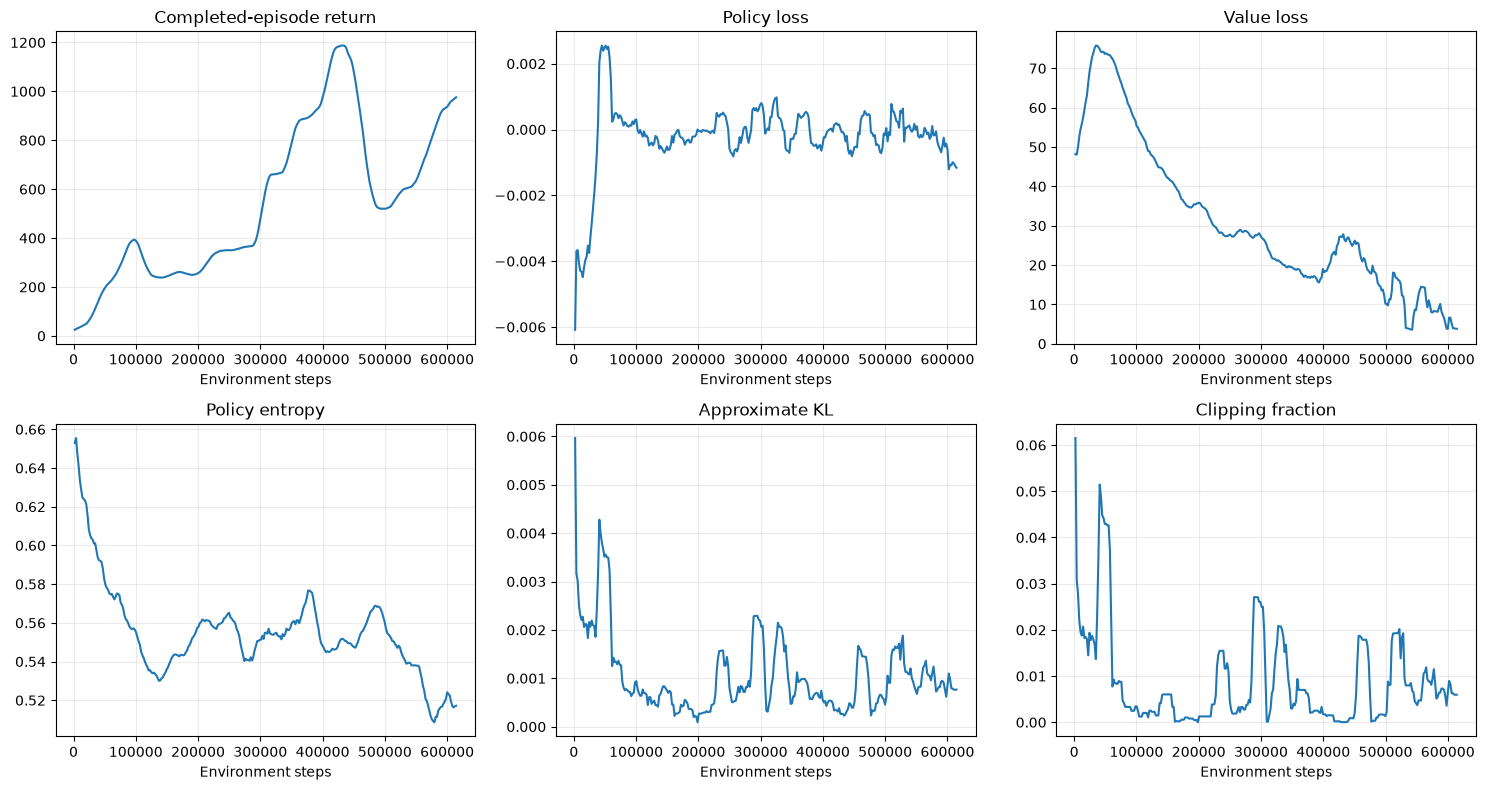

In [8]:
ppo_params, ppo_history = train_ppo(CFG)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
metrics = [
    ('train_episode_return', 'Completed-episode return'),
    ('actor_loss', 'Policy loss'),
    ('critic_loss', 'Value loss'),
    ('entropy', 'Policy entropy'),
    ('approx_kl', 'Approximate KL'),
    ('clip_fraction', 'Clipping fraction'),
]
for ax, (col, title) in zip(axes.flat, metrics):
    ax.plot(ppo_history.env_steps,
            ppo_history[col].rolling(10, min_periods=1).mean())
    ax.set(title=title, xlabel='Environment steps')
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Independent episodic evaluation

The same episode keys are used for all policy comparisons. Post-terminal rewards are zeroed, and both observation and environment state are frozen. We report sampled and greedy evaluation separately. A bootstrap interval here measures uncertainty across evaluation episodes **conditional on a single trained policy**; it is not a confidence interval across training seeds.

In [9]:
def eval_one(params, key, max_steps, greedy=False):
    rng, reset_key = jax.random.split(key)
    obs, state = env.reset(reset_key, env_params)
    def body(carry, _):
        obs, state, rng, done = carry
        rng, ak, ek = jax.random.split(rng, 3)
        logits, _ = model.apply(params, obs)
        action = jnp.argmax(logits) if greedy else jax.random.categorical(ak, logits)
        next_obs, next_state, reward, step_done = env_step(ek, state, action)
        reward = jnp.where(done, 0., reward)
        next_obs = jnp.where(done, obs, next_obs)
        next_state = jax.tree_util.tree_map(
            lambda old, new: jnp.where(done, old, new), state, next_state
        )
        return (next_obs, next_state, rng, done | step_done), reward
    _, rewards = jax.lax.scan(body, (obs, state, rng, jnp.bool_(False)),
                              None, length=max_steps)
    return rewards.sum()

@partial(jax.jit, static_argnames=('max_steps', 'greedy'))
def eval_batch(params, keys, max_steps=500, greedy=False):
    return jax.vmap(lambda k: eval_one(params, k, max_steps, greedy))(keys)

def evaluate(params, keys, greedy=False):
    return np.asarray(eval_batch(params, keys, CFG.max_episode_steps, greedy))

def bootstrap_ci(values, seed=42, n_boot=2000):
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    boot = rng.choice(values, (n_boot, len(values)), replace=True).mean(axis=1)
    return np.quantile(boot, [0.025, 0.975])

def evaluation_row(label, params, keys, greedy):
    returns = evaluate(params, keys, greedy)
    lo, hi = bootstrap_ci(returns)
    return dict(method=label, mode='greedy' if greedy else 'sampled',
                mean=returns.mean(), median=np.median(returns),
                std=returns.std(ddof=1), ci_low=lo, ci_high=hi)

eval_keys = jax.random.split(jax.random.PRNGKey(202604), CFG.eval_episodes)
ppo_eval = pd.DataFrame([evaluation_row('PPO', ppo_params, eval_keys, greedy)
                         for greedy in (False, True)])
display(ppo_eval.round(2))


,method,mode,mean,median,std,ci_low,ci_high
0,PPO,sampled,500.0,500.0,0.0,500.0,500.0
1,PPO,greedy,500.0,500.0,0.0,500.0,500.0


## 9. Ablation: PPO versus an unclipped surrogate

**Fairness:** Both methods use the same rollout budget, minibatch count, optimizer, and number of policy epochs. The unclipped method is *not* vanilla single-update actor-critic: it reuses stale on-policy data without PPO's clipped safeguard. This isolates the importance of clipping under repeated optimization. To avoid KL early stopping masking the difference, we disable it in this ablation.

      PPO | update  50 | return  292.4 | KL 0.0040 | clip frac 0.052
      PPO | update 100 | return  289.0 | KL 0.0002 | clip frac 0.000
      PPO | update 150 | return  276.5 | KL 0.0058 | clip frac 0.084
      PPO | update 200 | return  552.6 | KL 0.0004 | clip frac 0.000
      PPO | update 250 | return 1133.3 | KL 0.0014 | clip frac 0.008
      PPO | update 300 | return 1879.1 | KL 0.0003 | clip frac 0.000
unclipped | update  50 | return  273.0 | KL 0.0132 | clip frac 0.205
unclipped | update 100 | return  228.1 | KL 0.0014 | clip frac 0.006
unclipped | update 150 | return  660.4 | KL 0.0044 | clip frac 0.061
unclipped | update 200 | return  862.1 | KL 0.0009 | clip frac 0.007
unclipped | update 250 | return 1284.1 | KL 0.0003 | clip frac 0.000
unclipped | update 300 | return 1374.2 | KL 0.0001 | clip frac 0.000


,method,mode,mean,median,std,ci_low,ci_high
0,PPO clipped,sampled,498.500000,500.0,15.000000,495.50,500.0
1,Unclipped surrogate,sampled,496.059998,500.0,27.959999,489.89,500.0


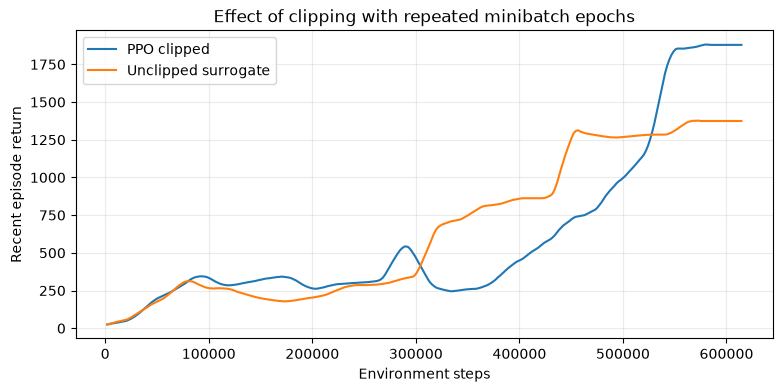

In [10]:
RUN_ABLATION = True
if RUN_ABLATION:
    ab_cfg = replace(CFG, target_kl=None)
    clipped_params, clipped_hist = train_ppo(ab_cfg, seed=0, clipped=True)
    unclipped_params, unclipped_hist = train_ppo(ab_cfg, seed=0, clipped=False)
    comparison = pd.DataFrame([
        evaluation_row('PPO clipped', clipped_params, eval_keys, False),
        evaluation_row('Unclipped surrogate', unclipped_params, eval_keys, False)
    ])
    display(comparison.round(2))
    fig, ax = plt.subplots(figsize=(9, 4))
    for label, hist in [('PPO clipped', clipped_hist),
                        ('Unclipped surrogate', unclipped_hist)]:
        ax.plot(hist.env_steps,
                hist.train_episode_return.rolling(10, min_periods=1).mean(),
                label=label)
    ax.set(xlabel='Environment steps', ylabel='Recent episode return',
           title='Effect of clipping with repeated minibatch epochs')
    ax.legend(); ax.grid(alpha=.25)
    plt.show()


## 10. Optional clipping-threshold sweep and multi-seed evaluation

In [12]:
RUN_CLIP_SWEEP = False
RUN_MULTISEED = False

if RUN_CLIP_SWEEP:
    clip_results = []
    for eps in (0.1, 0.2, 0.3):
        cfg = replace(CFG, clip_eps=eps)
        params, hist = train_ppo(cfg, verbose=False)
        result = evaluation_row(f'eps={eps}', params, eval_keys, False)
        result['clip_eps'] = eps
        clip_results.append(result)
    display(pd.DataFrame(clip_results).round(2))

if RUN_MULTISEED:
    rows = []
    for seed in (0, 1, 2, 3, 4):
        params, hist = train_ppo(CFG, seed=seed, verbose=False)
        # Shared evaluation keys for paired comparisons within a seed.
        keys = jax.random.split(jax.random.PRNGKey(20000 + seed), CFG.eval_episodes)
        scores = evaluate(params, keys)
        rows.append(dict(seed=seed, mean_return=scores.mean(),
                         median_return=np.median(scores)))
    multi = pd.DataFrame(rows)
    display(multi)
    print('Across-seed mean:', multi.mean_return.mean(),
          '| across-seed std:', multi.mean_return.std(ddof=1))


## 11. Interpretation and checklist

1. Does PPO learn CartPole under sampled evaluation, not just greedy evaluation?
2. Does the clipped surrogate behave more stably than an unclipped surrogate when **both** reuse minibatches?
3. Are KL and clip fraction small enough that optimization remains reasonably conservative? The KL threshold is a heuristic stopping criterion, not a guarantee.
4. How sensitive is performance to $\epsilon$, number of PPO epochs, and random seed?
5. How does PPO compare with Notebook 03's actor–critic under the **same environment-step budget**?

**Technical limitations:** Episode completion length is used as a training return for CartPole, where rewards are +1 per step. This notebook treats Gymnax time-limit termination as terminal. In tasks where truncation is distinct from true termination, preserve separate `terminated` and `truncated` flags and bootstrap at truncations appropriately. The optional value clipping uses the same numeric threshold as policy clipping, a common practical convention but not a mathematical requirement.

**Next:** Notebook 05 — Deep Q-Network (DQN), with replay buffers, target networks, and off-policy Bellman learning.